In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv("../data/raw/smoking_prediction.csv")

## EDA


##### Distribucion de genero y edad

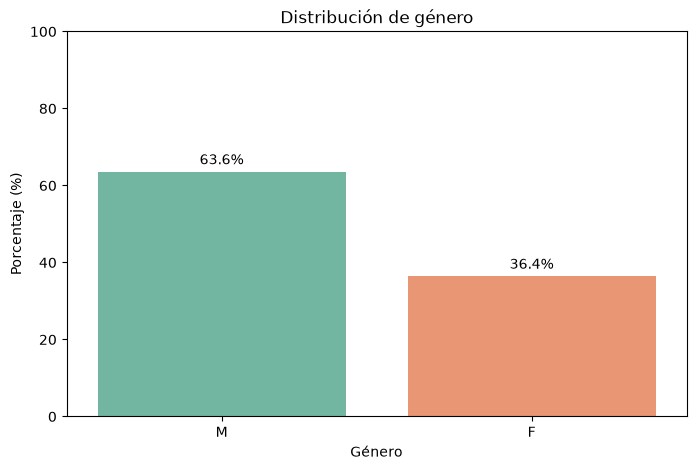

In [3]:

porcentajes = df["gender"].value_counts(normalize=True) * 100
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=porcentajes.index,
    y=porcentajes.values,
    hue=porcentajes.index,
    palette="Set2",
    legend=False
)

# Agregar porcentaje encima de cada barra
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.title("Distribución de género")
plt.xlabel("Género")
plt.ylabel("Porcentaje (%)")
plt.ylim(0, 100)
plt.show()


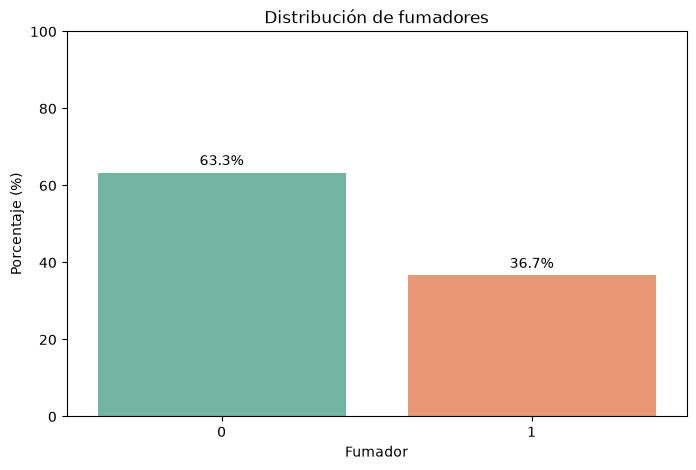

In [4]:
porcentajes = df["smoking"].value_counts(normalize=True) * 100
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=porcentajes.index,
    y=porcentajes.values,
    hue=porcentajes.index,
    palette="Set2",
    legend=False
)

# Agregar porcentaje encima de cada barra
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.title("Distribución de fumadores")
plt.xlabel("Fumador")
plt.ylabel("Porcentaje (%)")
plt.ylim(0, 100)
plt.show()

##### Distribucion de genero y edad segun fumador/no fumador

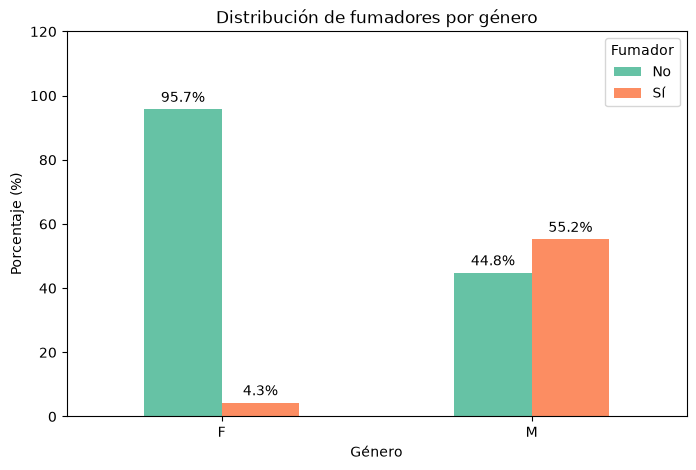

In [5]:
porcentajes_smoking = pd.crosstab(
    df["gender"],
    df["smoking"],
    normalize="index"
) * 100

ax = porcentajes_smoking.plot(
    kind="bar",
    figsize=(8, 5),
    color=["#66c2a5", "#fc8d62"]
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

ax.set_title("Distribución de fumadores por género")
ax.set_xlabel("Género")
ax.set_ylabel("Porcentaje (%)")
ax.set_ylim(0, 120)
ax.legend(title="Fumador", labels=["No", "Sí"])
plt.xticks(rotation=0)
plt.show()

In [6]:
df["age"].describe().T

count    50000.000000
mean        44.189300
std         12.090086
min         20.000000
25%         40.000000
50%         40.000000
75%         55.000000
max         85.000000
Name: age, dtype: float64

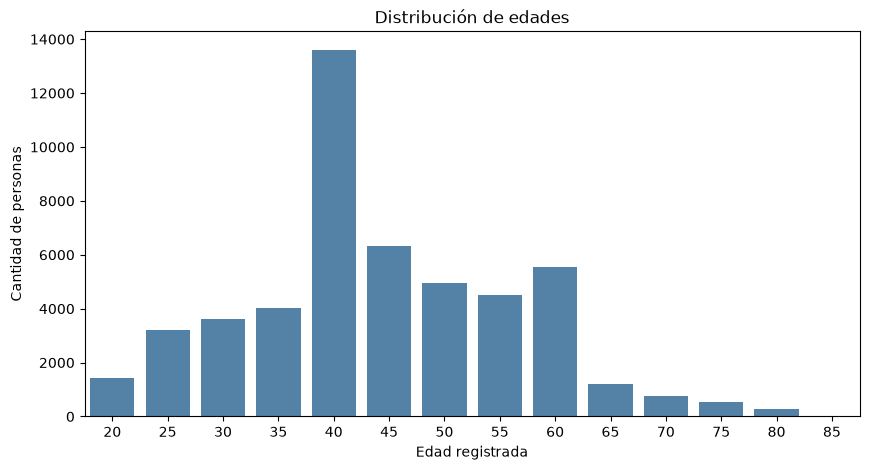

In [7]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="age",
    color="steelblue"
)

plt.title("Distribución de edades")
plt.xlabel("Edad registrada")
plt.ylabel("Cantidad de personas")
plt.show()

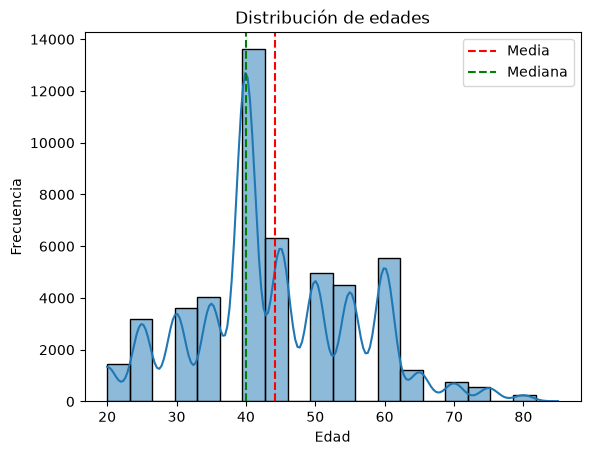

In [8]:
sns.histplot(data=df, x="age", bins=20, kde=True)

plt.axvline(df["age"].mean(), color="red",
            linestyle="--", label="Media")

plt.axvline(df["age"].median(), color="green",
            linestyle="--", label="Mediana")

plt.title("Distribución de edades")
plt.xlabel("Edad")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

In [9]:

print("\nFrecuencia por edad:")
print(df["age"].value_counts().sort_index())


Frecuencia por edad:
age
20     1430
25     3205
30     3623
35     4024
40    13604
45     6328
50     4969
55     4508
60     5531
65     1201
70      748
75      555
80      260
85       14
Name: count, dtype: int64


Nota: concentracion de datos dentro de los 40 años. Una media de 44,19 y una mediana de 40 sugieren asimetria positiva (edades elevadas influyen en el promedio). Las edades se encuentran agrupadas cada 5 años

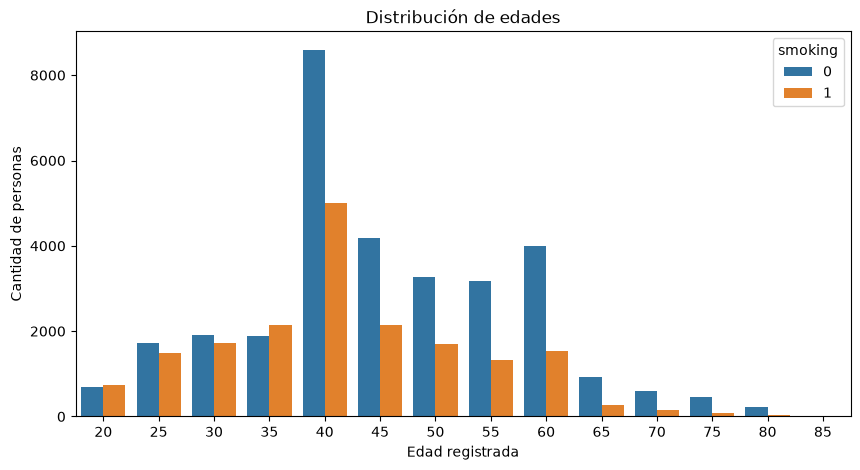

In [10]:
plt.figure(figsize=(10, 5))


sns.countplot(
    data=df,
    x="age",
    hue="smoking",
)

plt.title("Distribución de edades")
plt.xlabel("Edad registrada")
plt.ylabel("Cantidad de personas")
plt.show()

In [11]:
porcentajes_edad = pd.crosstab(
    df["age"],
    df["smoking"],
    normalize="index"
) * 100

print(porcentajes_edad.round(2))

smoking      0      1
age                  
20       48.53  51.47
25       53.51  46.49
30       52.64  47.36
35       46.99  53.01
40       63.17  36.83
45       66.20  33.80
50       65.77  34.23
55       70.67  29.33
60       72.12  27.88
65       77.69  22.31
70       79.68  20.32
75       83.78  16.22
80       88.85  11.15
85       92.86   7.14


#### Porcentaje de fumador y no fumador por edad

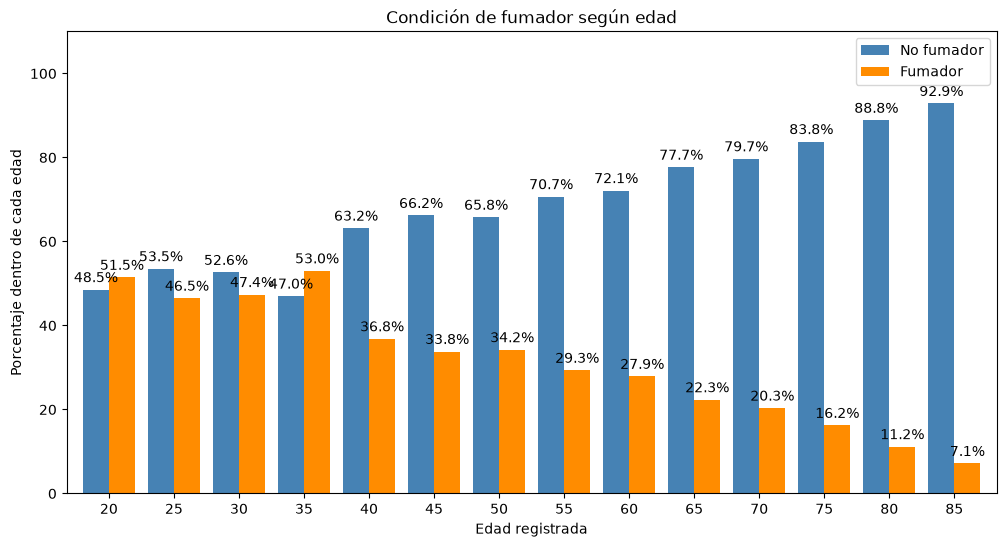

In [12]:

ax = porcentajes_edad.plot(
    kind="bar",
    figsize=(12, 6),
    color=["steelblue", "darkorange"],
    width=0.8
)

plt.title("Condición de fumador según edad")
plt.xlabel("Edad registrada")
plt.ylabel("Porcentaje dentro de cada edad")
plt.legend(["No fumador", "Fumador"])
plt.xticks(rotation=0)
plt.ylim(0, 110)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.show()

La proporción de fumadores disminuye a medida que aumenta la edad pero dado que hay mas no fumadores mujeres que hombres, puede estar influido por el genero. Se agrega el genero a la comparacion

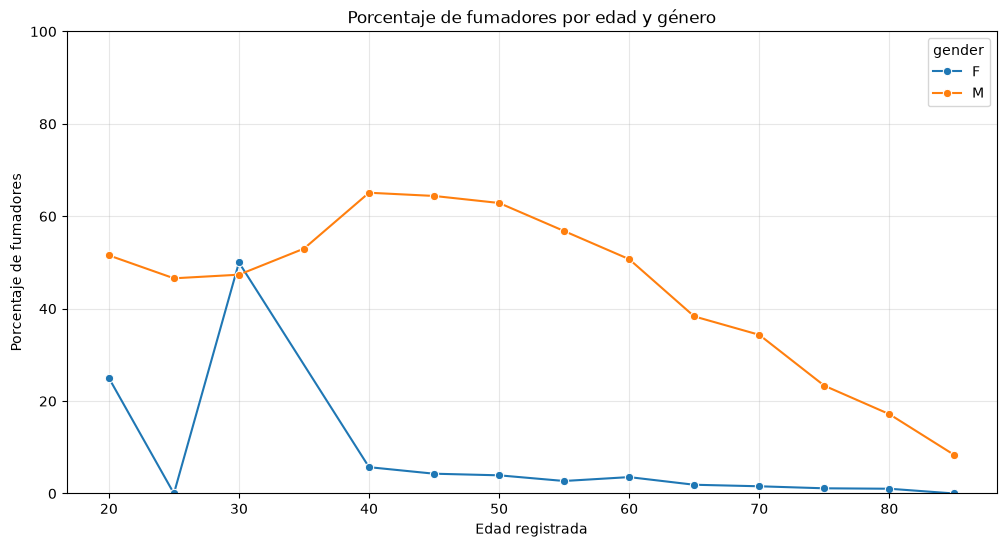

In [13]:
# Porcentaje de fumadores dentro de cada combinación
# de edad y género
edad_genero = (
    df.groupby(["age", "gender"])["smoking"]
    .agg(["mean", "count"])
    .reset_index()
)

edad_genero["porcentaje"] = edad_genero["mean"] * 100

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=edad_genero,
    x="age",
    y="porcentaje",
    hue="gender",
    marker="o"
)

plt.title("Porcentaje de fumadores por edad y género")
plt.xlabel("Edad registrada")
plt.ylabel("Porcentaje de fumadores")
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.show()

In [14]:
tabla = (
    df.groupby(["age", "gender"])["smoking"]
    .agg(
        cantidad="count",
        fumadores="sum",
        porcentaje="mean"
    )
    .reset_index()
)

tabla["porcentaje"] = tabla["porcentaje"] * 100

print(tabla.round(2).to_string(index=False))

 age gender  cantidad  fumadores  porcentaje
  20      F         4          1       25.00
  20      M      1426        735       51.54
  25      F         6          0        0.00
  25      M      3199       1490       46.58
  30      F         2          1       50.00
  30      M      3621       1715       47.36
  35      M      4024       2133       53.01
  40      F      6475        369        5.70
  40      M      7129       4641       65.10
  45      F      3221        138        4.28
  45      M      3107       2001       64.40
  50      F      2415         95        3.93
  50      M      2554       1606       62.88
  55      F      2290         62        2.71
  55      M      2218       1260       56.81
  60      F      2678         95        3.55
  60      M      2853       1447       50.72
  65      F       528         10        1.89
  65      M       673        258       38.34
  70      F       320          5        1.56
  70      M       428        147       34.35
  75      

Conclusiones hasta ahora : En los datos hay mayor cantidad de hombres (63,6%) que mujeres (36,4%).
Hay una asociación entre genero y la condicion de fumador: el 55,2% de los hombres está clasificado como fumador, frente al 4,3% de las mujeres.
En hombres entre 40 y 50 años es donde hay mayor proporcion de fumadores  y a partir de los 50 años comienza a disminuir. 
En mujeres se da un pico de fumadores a los 20 que luego cae a los 25 años y luego aumenta a los 30 años. Luego de los 40 se mantiene el porcentaje por debajo del 10%. En la tabla por edad vemos que estos datos son porque las mujeres  entre 20 y 30 años estan subrepresentadas 
Estas variables de edad y genero podrían  relevantes para predecir si son fumadores o no pero hay un desbalance de la distribucion por genero y edad que hay que tener en cuenta


#### Analisis de variables de altura , peso y cintura

In [15]:
variables = ["height(cm)", "weight(kg)", "waist(cm)"]

df.groupby("smoking")[variables].agg(
    ["mean", "median", "std"]
).round(2)

height(cm)              weight(kg)               waist(cm)         \
              mean median   std       mean median    std      mean median   
smoking                                                                     
0           161.88  160.0  9.28      62.94   60.0  12.34      3.35   3.33   
1           169.45  170.0  6.80      70.96   70.0  12.05      3.53   3.50   

               
          std  
smoking        
0        0.38  
1        0.36

In [16]:
variables = ["height(cm)", "weight(kg)", "waist(cm)"]

df.groupby(["gender", "smoking"])[variables].agg(
    ["mean", "median", "std", "count"]
).round(2)

height(cm)                     weight(kg)                       \
                     mean median   std  count       mean median    std  count   
gender smoking                                                                  
F      0           155.59  155.0  5.78  17437      56.13   55.0   8.54  17437   
       1           156.63  155.0  5.54    779      56.38   55.0   9.85    779   
M      0           169.58  170.0  6.53  14234      71.27   70.0  11.10  14234   
       1           170.02  170.0  6.27  17550      71.61   70.0  11.72  17550   

               waist(cm)                      
                    mean median   std  count  
gender smoking                                
F      0            3.20   3.17  0.36  17437  
       1            3.21   3.17  0.39    779  
M      0            3.53   3.50  0.34  14234  
       1            3.54   3.54  0.36  17550

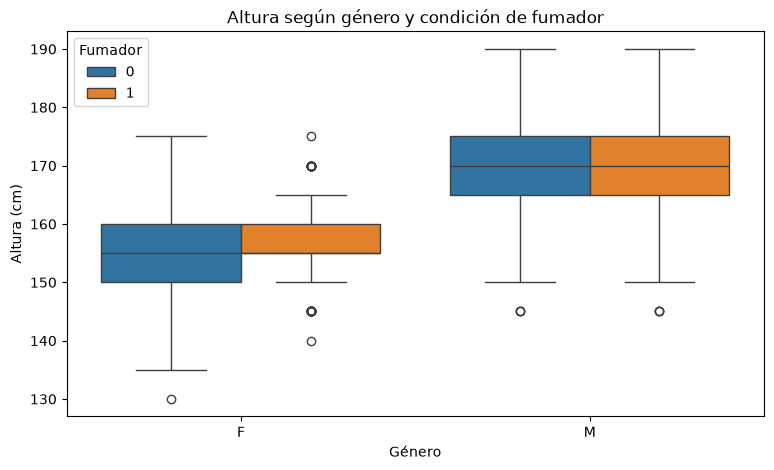

In [17]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="gender",
    y="height(cm)",
    hue="smoking"
)

plt.title("Altura según género y condición de fumador")
plt.xlabel("Género")
plt.ylabel("Altura (cm)")
plt.legend(title="Fumador")
plt.show()

Las distribuciones de altura tienen medianas similares dentro de los grupos de no fumadores y fumadores cuando se discrimina por genero

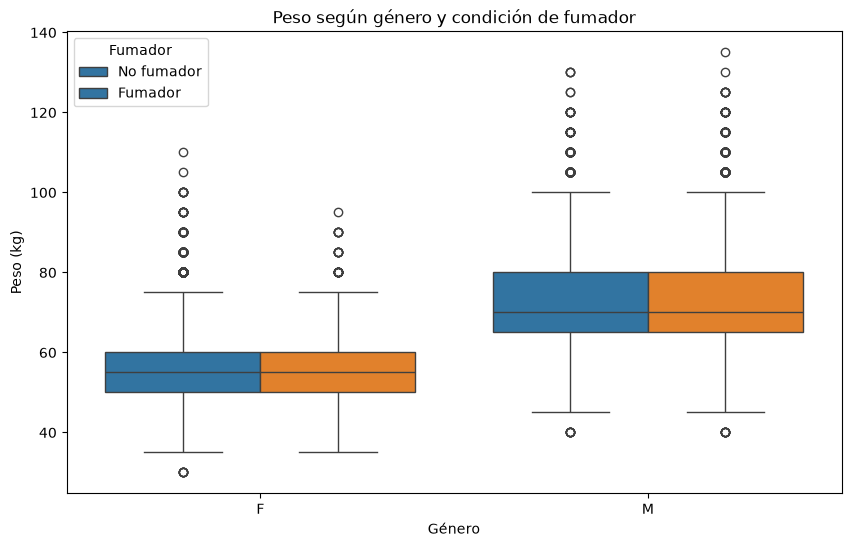

In [18]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="gender",
    y="weight(kg)",
    hue="smoking"
)

plt.title("Peso según género y condición de fumador")
plt.xlabel("Género")
plt.ylabel("Peso (kg)")
plt.legend(title="Fumador", labels=["No fumador", "Fumador"])
plt.show()

In [19]:
df.groupby(["gender", "smoking"])["weight(kg)"].agg(
    ["mean", "median", "std", "count"]
).round(2)

mean  median    std  count
gender smoking                             
F      0        56.13    55.0   8.54  17437
       1        56.38    55.0   9.85    779
M      0        71.27    70.0  11.10  14234
       1        71.61    70.0  11.72  17550

En cuanto al peso sucede lo mismo que la altura: Cuando aperturamos por genero las medias son similares

#### Analsis de variables clinicas

In [20]:
variables_clinicas = [
    "fasting blood sugar",
    "Cholesterol",
    "triglyceride",
    "hemoglobin"
]

df.groupby("smoking")[variables_clinicas].agg(
    ["mean", "median", "std"]
).round(2)

fasting blood sugar              Cholesterol               \
                       mean median   std        mean median   std   
smoking                                                             
0                      4.07   3.96  0.76        8.24   8.17  1.51   
1                      4.25   4.04  1.02        8.15   8.08  1.52   

        triglyceride              hemoglobin               
                mean median   std       mean median   std  
smoking                                                    
0               4.71    4.0  2.64       0.57   0.58  0.07  
1               6.26    5.5  3.27       0.63   0.63  0.05

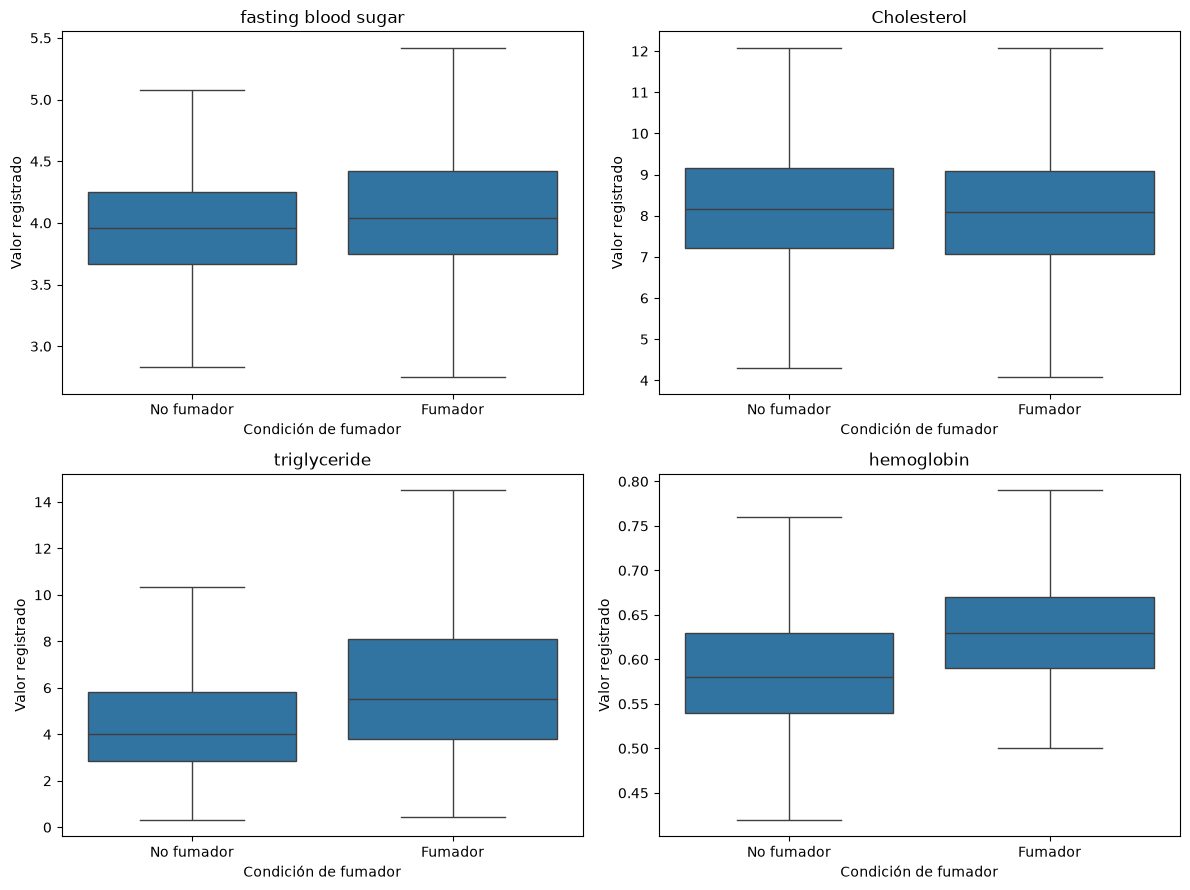

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

variables_clinicas = [
    "fasting blood sugar",
    "Cholesterol",
    "triglyceride",
    "hemoglobin"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, variable in zip(axes.flat, variables_clinicas):
    sns.boxplot(
        data=df,
        x="smoking",
        y=variable,
        ax=ax,
        showfliers=False
    )

    ax.set_title(variable)
    ax.set_xlabel("Condición de fumador")
    ax.set_ylabel("Valor registrado")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["No fumador", "Fumador"])

plt.tight_layout()
plt.show()

In [22]:
variables = ["triglyceride", "hemoglobin"]

df.groupby(["gender", "smoking"])[variables].agg(
    ["mean", "median", "std", "count"]
).round(2)

triglyceride                     hemoglobin                    
                       mean median   std  count       mean median   std  count
gender smoking                                                                
F      0               4.29   3.67  2.38  17437       0.53   0.54  0.05  17437
       1               5.12   4.25  2.98    779       0.55   0.55  0.05    779
M      0               5.22   4.50  2.85  14234       0.63   0.63  0.04  14234
       1               6.31   5.54  3.27  17550       0.63   0.63  0.05  17550

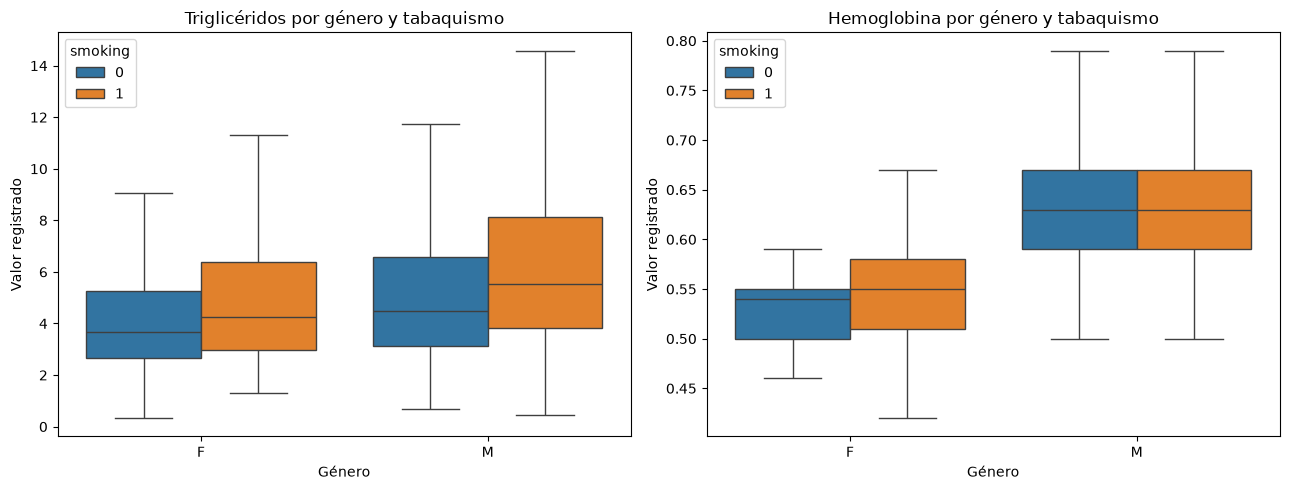

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    data=df,
    x="gender",
    y="triglyceride",
    hue="smoking",
    showfliers=False,
    ax=axes[0]
)

axes[0].set_title("Triglicéridos por género y tabaquismo")
axes[0].set_xlabel("Género")
axes[0].set_ylabel("Valor registrado")

sns.boxplot(
    data=df,
    x="gender",
    y="hemoglobin",
    hue="smoking",
    showfliers=False,
    ax=axes[1]
)

axes[1].set_title("Hemoglobina por género y tabaquismo")
axes[1].set_xlabel("Género")
axes[1].set_ylabel("Valor registrado")

plt.tight_layout()
plt.show()

El análisis evidencia diferencias descriptivas entre fumadores y no fumadores en algunas variables clínicas como trigliceridos y hemoglobina.

Los triglicéridos presentan una mediana superior en fumadores (5,50) respecto de no fumadores (4,00), acompañada de una mayor dispersión. Esta diferencia de trigliceridos se mantiene al aperturar por genero

La hemoglobina también presenta valores centrales superiores entre fumadores, con medianas de 0,63 y 0,58, respectivamente. Al abrir por genero estas diferencias disminuyen considerablemente

Por el contrario, la glucosa en ayunas presenta diferencias pequeñas y el colesterol muestra distribuciones centrales  similares entre ambos grupos.



#### Correlaciones

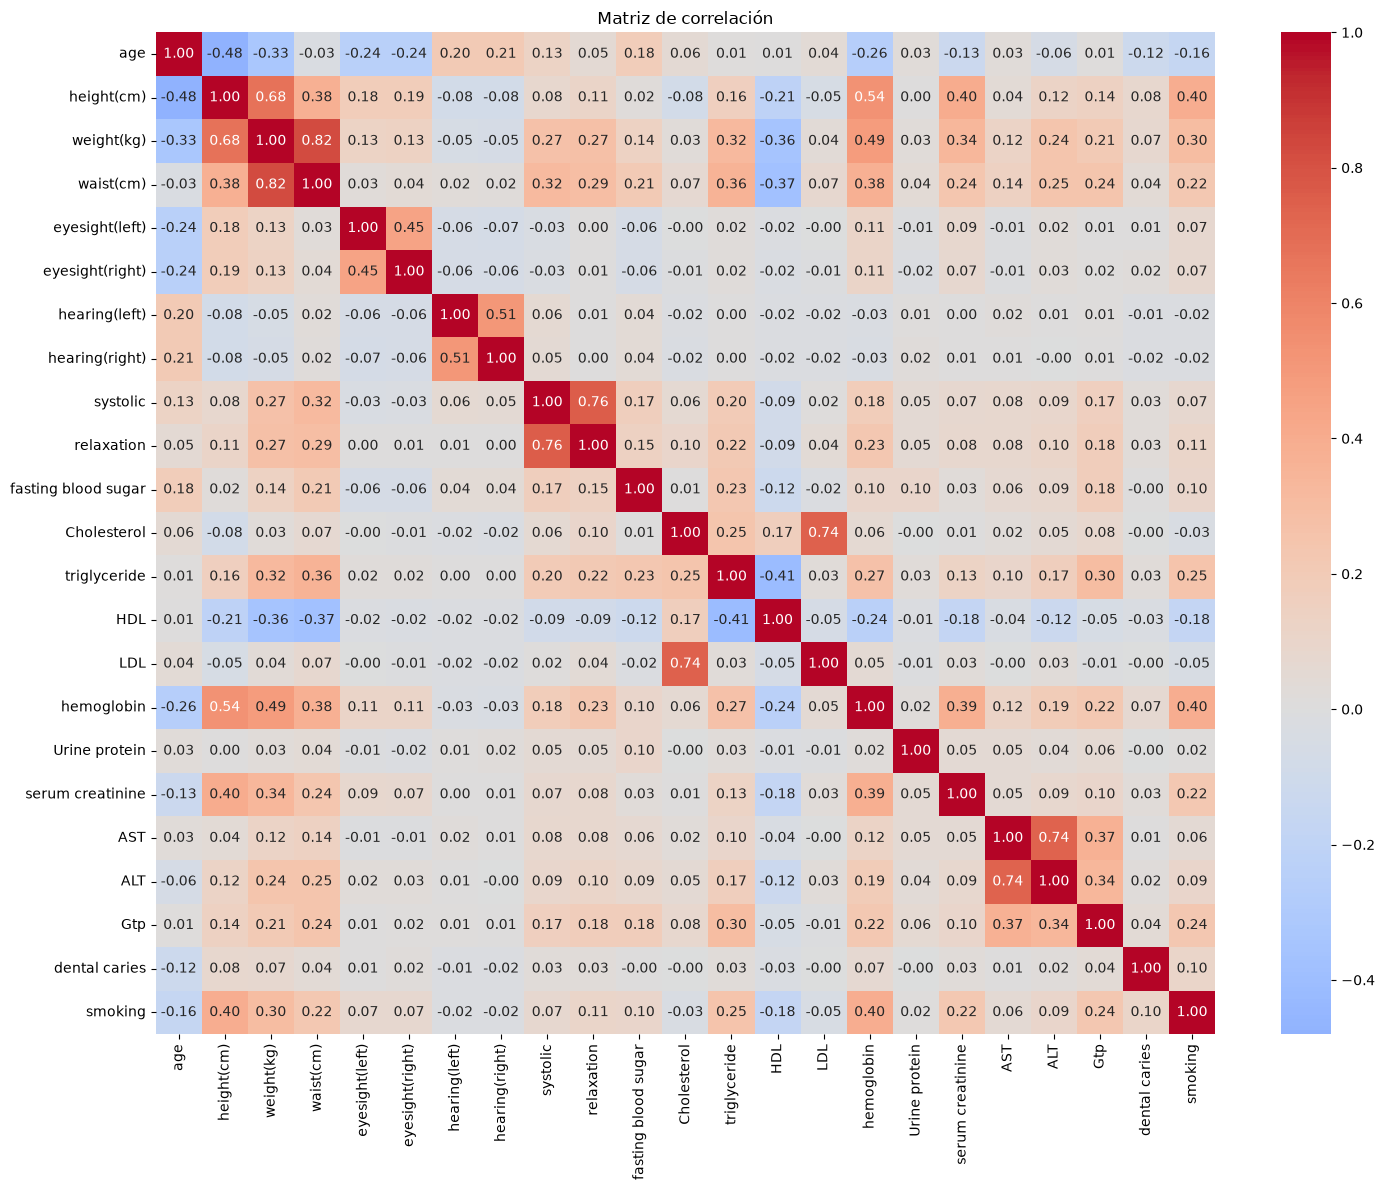

In [24]:
df_corr = df.select_dtypes(include="number").drop(
    columns=["ID"],
    errors="ignore"
)

correlacion = df_corr.corr()

plt.figure(figsize=(15, 12))

sns.heatmap(
    correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Matriz de correlación")
plt.tight_layout()
plt.show()

In [25]:
print("Tartar:")
print(df["tartar"].value_counts())

print("\nDental caries:")
print(df["dental caries"].value_counts())

Tartar:
tartar
Y    27789
N    22211
Name: count, dtype: int64

Dental caries:
dental caries
0    39344
1    10656
Name: count, dtype: int64


In [26]:
porcentajes_tartar = pd.crosstab(
    df["tartar"],
    df["smoking"],
    normalize="index"
) * 100

print(porcentajes_tartar.round(2))

smoking      0      1
tartar               
N        68.74  31.26
Y        59.03  40.97


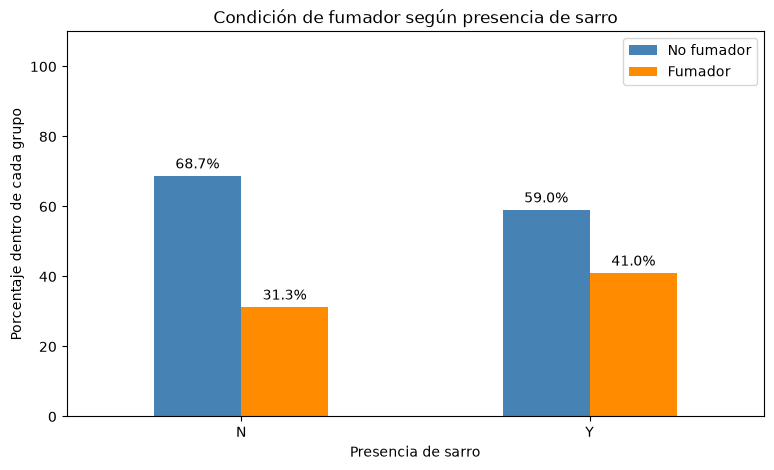

In [27]:
ax = porcentajes_tartar.plot(
    kind="bar",
    figsize=(9, 5),
    color=["steelblue", "darkorange"]
)

plt.title("Condición de fumador según presencia de sarro")
plt.xlabel("Presencia de sarro")
plt.ylabel("Porcentaje dentro de cada grupo")
plt.legend(["No fumador", "Fumador"])
plt.xticks(rotation=0)
plt.ylim(0, 110)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.show()

In [28]:
porcentajes_caries = pd.crosstab(
    df["dental caries"],
    df["smoking"],
    normalize="index"
) * 100

print(porcentajes_caries.round(2))

smoking            0      1
dental caries              
0              65.94  34.06
1              53.73  46.27


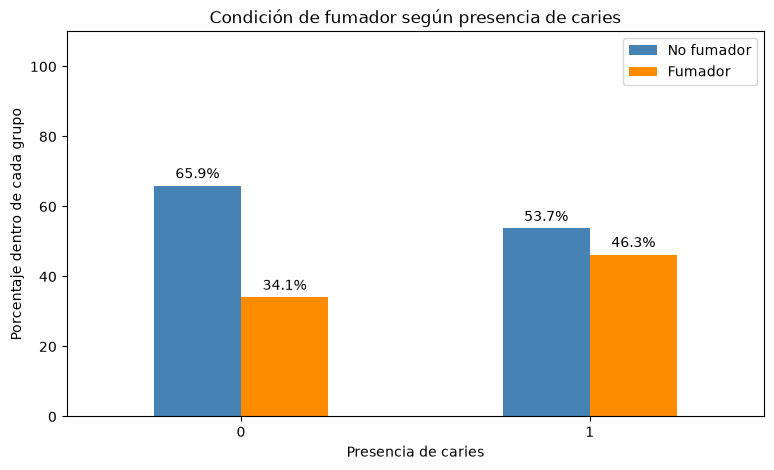

In [29]:
ax = porcentajes_caries.plot(
    kind="bar",
    figsize=(9, 5),
    color=["steelblue", "darkorange"]
)

plt.title("Condición de fumador según presencia de caries")
plt.xlabel("Presencia de caries")
plt.ylabel("Porcentaje dentro de cada grupo")
plt.legend(["No fumador", "Fumador"])
plt.xticks(rotation=0)
plt.ylim(0, 110)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.show()

In [30]:
# Porcentaje de fumadores según género y caries
caries_genero = pd.crosstab(
    [df["gender"], df["dental caries"]],
    df["smoking"],
    normalize="index"
) * 100

print(caries_genero.round(2))

# Porcentaje de fumadores según género y sarro
sarro_genero = pd.crosstab(
    [df["gender"], df["tartar"]],
    df["smoking"],
    normalize="index"
) * 100

print(sarro_genero.round(2))

smoking                   0      1
gender dental caries              
F      0              96.09   3.91
       1              93.89   6.11
M      0              47.03  52.97
       1              37.66  62.34
smoking            0      1
gender tartar              
F      N       96.76   3.24
       Y       94.77   5.23
M      N       50.52  49.48
       Y       40.57  59.43


La asociación entre caries, sarro y tabaquismo se mantiene al separar por sexo pero difieren en magnitud
La proporcion de fumadores es mayor en los que tienen caries en ambos sexos aunque en hombres aumenta a casi 10% (de 52,97% a 62,34%.) En resumen, la tendencia inicial de que es mayor la cantidad de fumadores con caries se mantiene al abrir por sexo.
En cuanto a sarro hay un comportamiento similar:  en mujeres la proporción de fumadoras es mayor entre quienes tienen sarro y en hombres también es mayor con una diferencia de casi 10%


#### Valores atipicos

In [31]:
variables = [
    "height(cm)",
    "weight(kg)",
    "waist(cm)",
    "systolic",
    "relaxation",
    "fasting blood sugar",
    "Cholesterol",
    "triglyceride",
    "HDL",
    "LDL",
    "hemoglobin",
    "serum creatinine",
    "AST",
    "ALT",
    "Gtp"
]

resultados = []

for variable in variables:

    Q1 = df[variable].quantile(0.25)
    Q3 = df[variable].quantile(0.75)

    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = (
        (df[variable] < limite_inferior) |
        (df[variable] > limite_superior)
    )

    cantidad = outliers.sum()
    porcentaje = cantidad / len(df) * 100

    resultados.append({
        "Variable": variable,
        "Outliers": cantidad,
        "Porcentaje": round(porcentaje, 2)
    })

df_outliers = pd.DataFrame(resultados)

df_outliers.sort_values(
    by="Porcentaje",
    ascending=False
)

,Variable,Outliers,Porcentaje
14,Gtp,4330,8.66
13,ALT,3506,7.01
5,fasting blood sugar,2987,5.97
12,AST,2698,5.40
7,triglyceride,2013,4.03
10,hemoglobin,966,1.93
8,HDL,903,1.81
4,relaxation,636,1.27
3,systolic,619,1.24
9,LDL,575,1.15


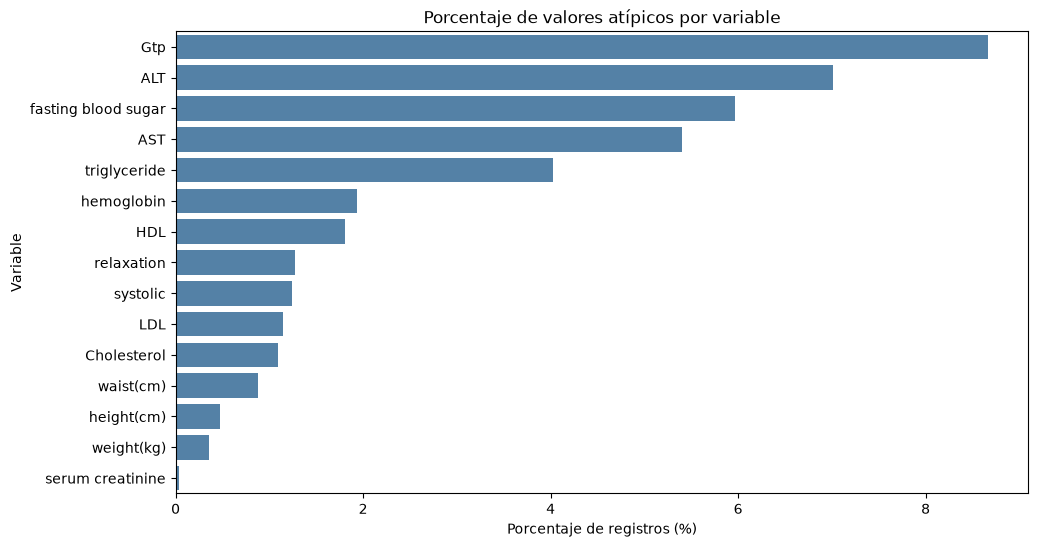

In [32]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=df_outliers.sort_values("Porcentaje", ascending=False),
    x="Porcentaje",
    y="Variable",
    color="steelblue"
)

plt.title("Porcentaje de valores atípicos por variable")
plt.xlabel("Porcentaje de registros (%)")
plt.ylabel("Variable")
plt.show()

Se identificaron valores atípicos en variables clínicas como Gtp, ALT, glucosa en ayunas y AST.
Las variables de altura y peso presentan una proporción menor de valores atípicos pero no necesariamente representan errores ya que podrían corresponder a variaciones reales de las mediciones.
Por este motivo, se decide conservar inicialmente los valores atípicos y evaluar su tratamiento durante la preparación y entrenamiento del modelo predictivo.

#### Conclusiones

El conjunto contiene 50.000 registros y 27 variables, sin valores nulos ni filas completamente duplicadas.

La variable objetivo smoking presenta un desbalance moderado, con un 63,34% de no fumadores y un 36,66% de fumadores.

Se identificó una asociación importante entre género y tabaquismo, así como diferencias en la proporción de fumadores según la edad.

Entre las variables clínicas, los triglicéridos presentan valores centrales superiores entre fumadores, incluso al segmentar por género. También se observaron asociaciones entre tabaquismo y presencia de caries y sarro dental.

Se identificaron valores atípicos principalmente en Gtp, ALT, glucosa en ayunas y AST, que se conservarán inicialmente para su posterior evaluación.

Se detectó que la variable oral es constante y que ID corresponde a un identificador, por lo que ambas son candidatas a excluir del conjunto de variables predictoras.